## Machine Learning Project Portfolio: Satellite Image Classification

**The notebook compiles a sequence of machine learning tasks focused on transitioning to classification problems and analyzing a 36-feature satellite imagery dataset. The satellite imagery dataset consists of 36 input features (V1 through V36) that represent measurements of various spectral light bands across a grid of adjacent pixels used to predict specific land classes.**  
**Project Progression:**  **Data Exploration and Correlation:** The project introduces the satellite dataset by analyzing 36 spectral input features, comparing class distributions, and plotting correlation heatmaps to identify redundancies across different pixels and light bands.  
**Classifier Comparison and Threshold Optimization:** The analysis compares Logistic Regression, Linear Discriminant Analysis (LDA), and Quadratic Discriminant Analysis (QDA) using ROC curves and validation AUC. Decision thresholds are then specifically optimized to minimize total costs based on a hypothetical scenario where false negatives carry a higher penalty than false positives.  
**Model Stability & Data Reduction:** The final phase tests model robustness by randomly restricting the training data to a 20% sample. The classifiers are retrained on this reduced subset, and the resulting decrease in validation AUC is calculated to evaluate how data scarcity impacts each model's predictive performance. 

**Data Inspection**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sat_train = pd.read_csv("satellite_train.csv")

rows, cols = sat_train.shape
print(f"Number of rows: {rows}")
print(f"Number of columns: {cols}")

missing_values = sat_train.isna().sum().sum()
print(f"Number of missing values: {missing_values}")

print("\nNumber of rows in each class (V37):")
print(sat_train['V37'].value_counts().sort_index())

Number of rows: 4435
Number of columns: 37
Number of missing values: 0

Number of rows in each class (V37):
V37
1    1072
2     479
3     961
4     415
5     470
7    1038
Name: count, dtype: int64


**Correlation Heatmap**

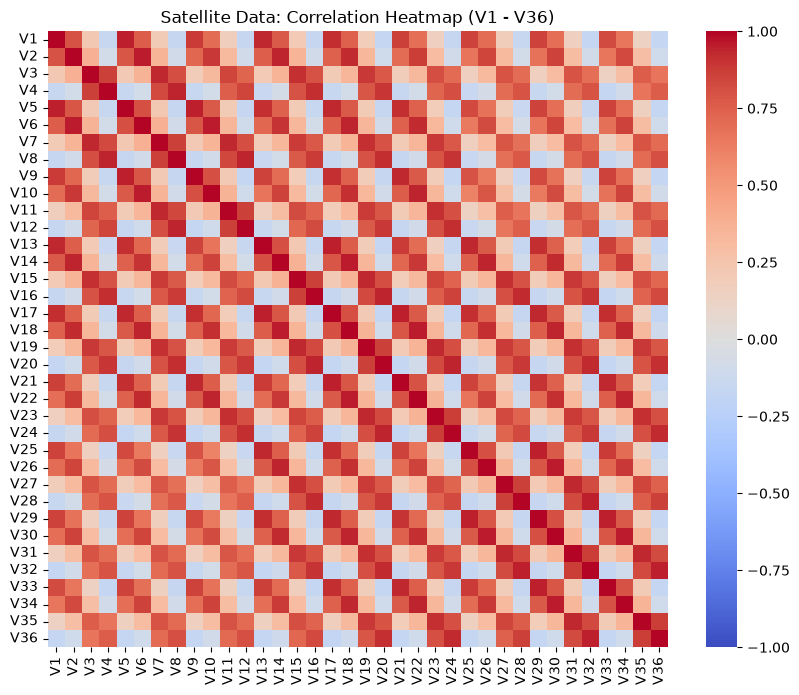

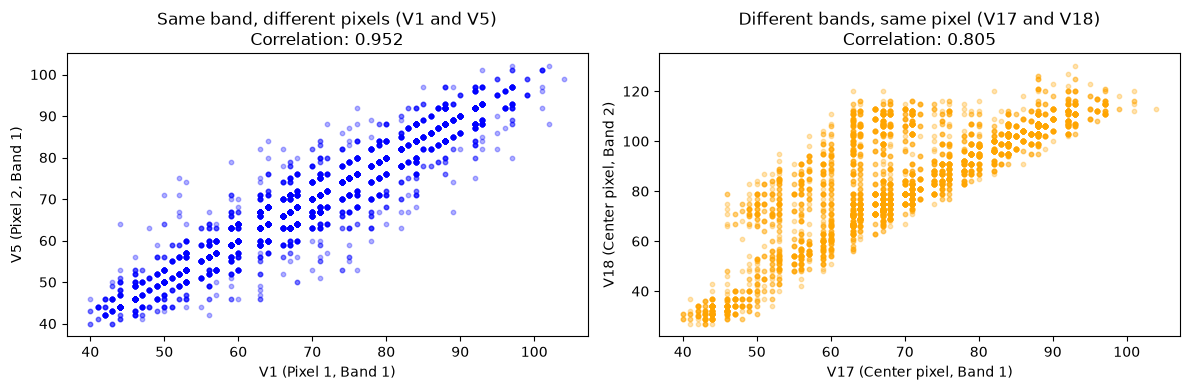

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

sat_features = sat_train.loc[:, 'V1':'V36']

corr_matrix = sat_features.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Satellite Data: Correlation Heatmap (V1 - V36)")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

corr_same_band = sat_train['V1'].corr(sat_train['V5'])
axes[0].scatter(sat_train['V1'], sat_train['V5'], alpha=0.3, s=10, color='blue')
axes[0].set_title(f"Same band, different pixels (V1 and V5)\nCorrelation: {corr_same_band:.3f}")
axes[0].set_xlabel("V1 (Pixel 1, Band 1)")
axes[0].set_ylabel("V5 (Pixel 2, Band 1)")

corr_diff_band = sat_train['V17'].corr(sat_train['V18'])
axes[1].scatter(sat_train['V17'], sat_train['V18'], alpha=0.3, s=10, color='orange')
axes[1].set_title(f"Different bands, same pixel (V17 and V18)\nCorrelation: {corr_diff_band:.3f}")
axes[1].set_xlabel("V17 (Center pixel, Band 1)")
axes[1].set_ylabel("V18 (Center pixel, Band 2)")

plt.tight_layout()
plt.show()

The satellite features exhibit high redundancy, showing a near-perfect correlation (0.952) when measuring the same spectral band across adjacent pixels, and a strong correlation (0.805) across different bands within the same pixel.

**Class Distributions**

--- Class Distribution (Fit vs Validation) ---


,fit,validation
actual class,,
0,311,104
1,778,260


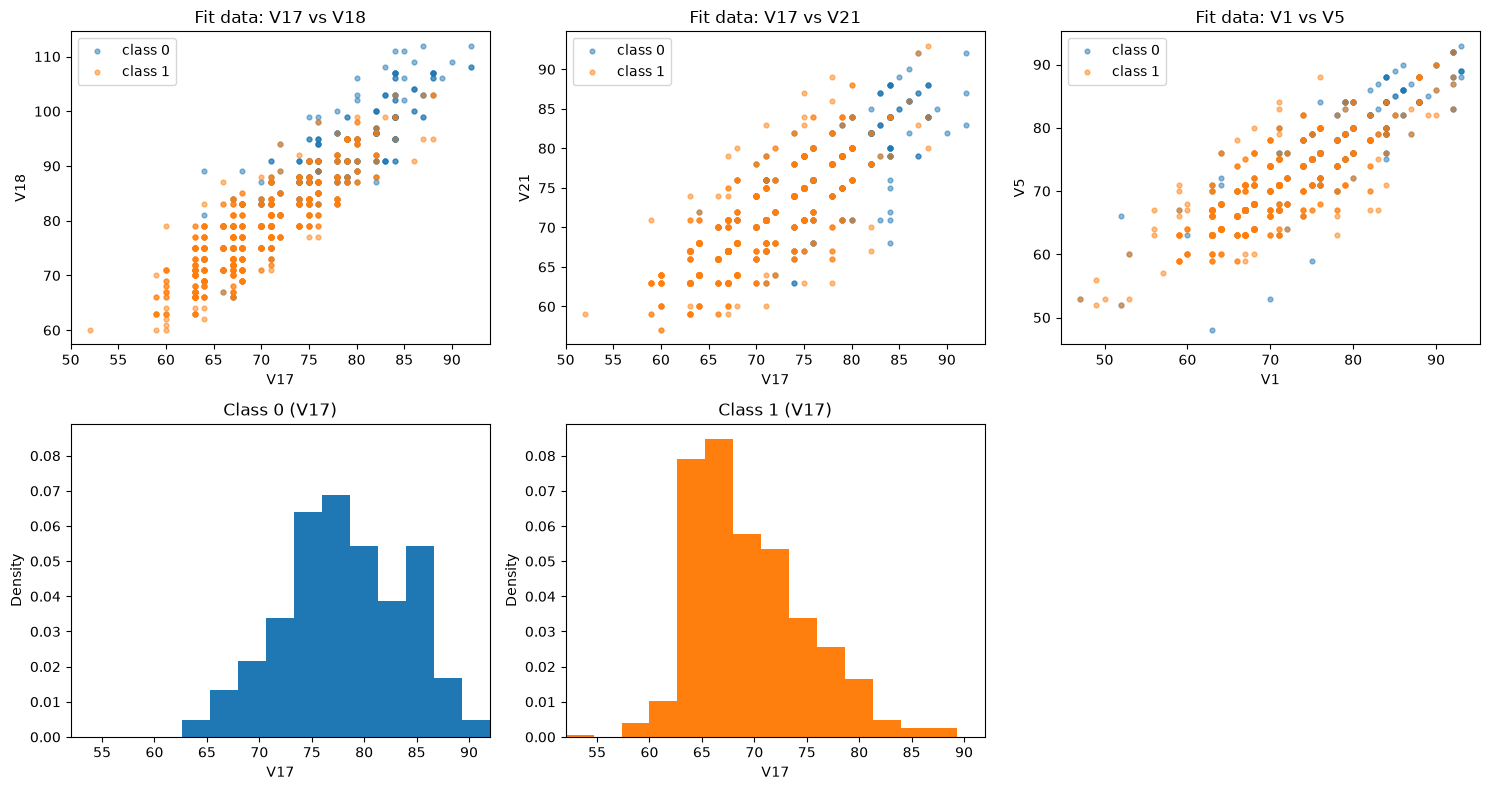

In [4]:
from sklearn.model_selection import train_test_split
from IPython.display import display

pd.set_option('display.precision', 3)

data = sat_train[sat_train['V37'].isin([4, 7])].copy()
data['y'] = (data['V37'] == 7).astype(int) 
features = [f'V{i}' for i in range(1, 37)]

fit, validation = train_test_split(
    data, test_size=0.25, stratify=data['y'], random_state=1601
)
y_fit, y_val = fit['y'], validation['y']

print("--- Class Distribution (Fit vs Validation) ---")
display(pd.DataFrame({
    'fit': y_fit.value_counts(), 'validation': y_val.value_counts()
}).sort_index().rename_axis('actual class'))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

bins = np.linspace(fit['V17'].min(), fit['V17'].max(), 16)

for label, color in [(0, 'tab:blue'), (1, 'tab:orange')]:
    part = fit[fit['y'] == label]
    
    axes[0, 0].scatter(part['V17'], part['V18'], s=12, alpha=0.5, color=color, label=f'class {label}')
    axes[0, 1].scatter(part['V17'], part['V21'], s=12, alpha=0.5, color=color, label=f'class {label}')
    axes[0, 2].scatter(part['V1'], part['V5'], s=12, alpha=0.5, color=color, label=f'class {label}')
    
    axes[1, label].hist(part['V17'], bins=bins, density=True, color=color)
    axes[1, label].set(title=f'Class {label} (V17)', xlabel='V17', ylabel='Density')

axes[0, 0].set(xlabel='V17', ylabel='V18', title='Fit data: V17 vs V18')
axes[0, 0].legend()
axes[0, 1].set(xlabel='V17', ylabel='V21', title='Fit data: V17 vs V21')
axes[0, 1].legend()
axes[0, 2].set(xlabel='V1', ylabel='V5', title='Fit data: V1 vs V5')
axes[0, 2].legend()

axes[1, 0].set_xlim(bins[0], bins[-1])
axes[1, 1].set_xlim(bins[0], bins[-1])
top = max(axes[1, 0].get_ylim()[1], axes[1, 1].get_ylim()[1])
axes[1, 0].set_ylim(0, top)
axes[1, 1].set_ylim(0, top)

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

The scatter plots reveal strong positive correlations between the spectral features, with both classes displaying similar orientations and spreads that suggest comparable covariance structures—an ideal condition for Linear Discriminant Analysis (LDA). Additionally, while the classes overlap, the histograms show roughly normal distributions with distinct centers, as Class 0 generally exhibits higher values for feature V17 than Class 1.

**Model Training**

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
X_fit = fit[features]
X_val = validation[features]

scaler = StandardScaler()
X_fit_scaled = scaler.fit_transform(X_fit)
X_val_scaled = scaler.transform(X_val)

models = {
    'Logistic': LogisticRegression(max_iter=5000), 
    'LDA': LDA(),
    'QDA': QDA()
}

val_probabilities = {}
fit_probabilities = {} 

print("Starting model training:")
for name, model in models.items():
    model.fit(X_fit_scaled, y_fit)
    
    fit_probabilities[name] = model.predict_proba(X_fit_scaled)[:, 1]
    val_probabilities[name] = model.predict_proba(X_val_scaled)[:, 1]
    
    print(f"- {name} trained successfully.")

Starting model training:
- Logistic trained successfully.
- LDA trained successfully.
- QDA trained successfully.


**ROC Curves**

AUC Results:
----------------------------------------
Logistic - Fit AUC: 0.9197 | Validation AUC: 0.9078
LDA      - Fit AUC: 0.9182 | Validation AUC: 0.9065
QDA      - Fit AUC: 0.9652 | Validation AUC: 0.8915
----------------------------------------


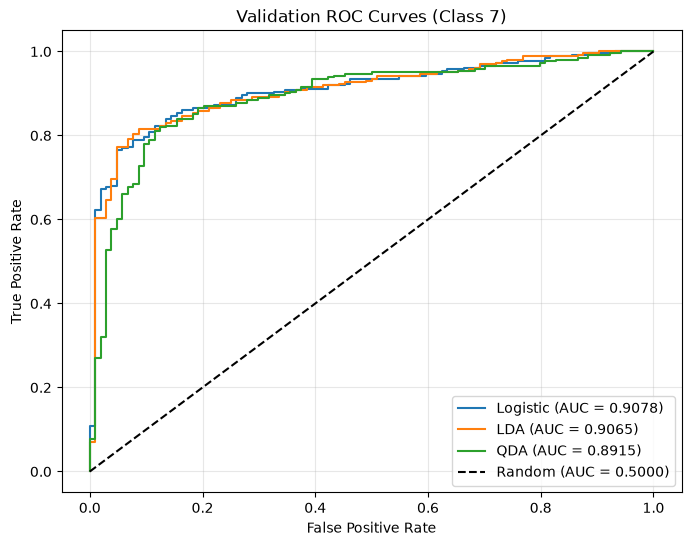

In [7]:
from sklearn.metrics import roc_curve, auc

print("AUC Results:")
print("-" * 40)

roc_data = {}

for name in models.keys():
    fpr_fit, tpr_fit, _ = roc_curve(y_fit, fit_probabilities[name])
    auc_fit = auc(fpr_fit, tpr_fit)
    
    fpr_val, tpr_val, _ = roc_curve(y_val, val_probabilities[name])
    auc_val = auc(fpr_val, tpr_val)
    
    roc_data[name] = (fpr_val, tpr_val, auc_val)
    
    print(f"{name:8} - Fit AUC: {auc_fit:.4f} | Validation AUC: {auc_val:.4f}")

print("-" * 40)

plt.figure(figsize=(8, 6))

for name, (fpr, tpr, roc_auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5000)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Validation ROC Curves (Class 7)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

While the more complex Quadratic Discriminant Analysis (QDA) model achieves the highest training AUC (0.9652), it suffers from overfitting and generalizes poorly to unseen data, yielding the lowest validation AUC (0.8915). In contrast, the simpler Logistic Regression and Linear Discriminant Analysis (LDA) models generalize much better, with Logistic Regression slightly outperforming the others to achieve the highest validation AUC of 0.9078.

**Threshold Optimization**

In [11]:
from sklearn.metrics import (
    mean_squared_error, 
    r2_score, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    confusion_matrix, 
    classification_report,
    roc_curve, 
    auc, 
    roc_auc_score
)
def scores_at(y, probability, threshold):
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    
    if tp + fp == 0:
        precision = 0  
    else:
        precision = tp / (tp + fp)
        
    recall = tp / (tp + fn)
    specificity = tn / (tn + fp)
    false_positive_rate = fp / (fp + tn)
    
    return {
        'threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'accuracy': (tn + tp) / len(y), 'precision': precision,
        'recall': recall, 'F1': 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0,
        'specificity': specificity, 'J': recall - false_positive_rate,
        'cost': 5 * fn + fp,
    }

selected_model = 'Logistic'
p_val = val_probabilities[selected_model]

candidates = np.append(np.linspace(0, 1, 101), 1.01)

results = []
for threshold in candidates:
    result = scores_at(y_val, p_val, threshold)
    results.append(result)
    
grid = pd.DataFrame(results)

best_j_row = grid['J'].idxmax()
best_f1_row = grid['F1'].idxmax()
best_cost_row = grid['cost'].idxmin()

thresholds = {
    'Fixed 0.50': 0.50,
    'Youden J': grid.loc[best_j_row, 'threshold'],
    'F1': grid.loc[best_f1_row, 'threshold'],
    'Cost (5, 1)': grid.loc[best_cost_row, 'threshold'],
}

summary_results = []
for rule, threshold in thresholds.items():
    res = scores_at(y_val, p_val, threshold)
    res['rule'] = rule
    summary_results.append(res)

summary = pd.DataFrame(summary_results).set_index('rule')
columns = ['threshold', 'accuracy', 'precision', 'recall', 'F1', 'specificity', 'cost']

print(f"--- Summary Table for {selected_model} ---")
display(summary[columns].round(3))

for rule, row in summary.iterrows():
    matrix = [[int(row['TN']), int(row['FP'])],
              [int(row['FN']), int(row['TP'])]]
    print(f"\n{rule}: threshold = {row['threshold']:.2f}")
    display(pd.DataFrame(matrix, index=['actual 0', 'actual 1'],
                         columns=['predicted 0', 'predicted 1']))

--- Summary Table for Logistic ---


,threshold,accuracy,precision,recall,F1,specificity,cost
rule,,,,,,,
Fixed 0.50,0.50,0.824,0.853,0.912,0.881,0.606,156
Youden J,0.76,0.841,0.947,0.823,0.881,0.885,242
F1,0.59,0.849,0.890,0.900,0.895,0.721,159
"Cost (5, 1)",0.09,0.742,0.736,0.996,0.846,0.106,98



Fixed 0.50: threshold = 0.50


,predicted 0,predicted 1
actual 0,63,41
actual 1,23,237



Youden J: threshold = 0.76


,predicted 0,predicted 1
actual 0,92,12
actual 1,46,214



F1: threshold = 0.59


,predicted 0,predicted 1
actual 0,75,29
actual 1,26,234



Cost (5, 1): threshold = 0.09


,predicted 0,predicted 1
actual 0,11,93
actual 1,1,259


To minimize total costs—where a false negative is penalized five times more heavily than a false positive—the optimal decision threshold must be drastically lowered to 0.09. While this aggressive threshold maximizes recall to 99.6% by successfully catching 259 out of 260 true positives, it severely sacrifices specificity, incorrectly classifying 93 out of 104 actual negatives as positives. Conversely, optimizing for Youden's J statistic raises the threshold to 0.76, which improves specificity to 88.5% but results in missing 46 true positives, demonstrating the fundamental trade-off between capturing all target instances and avoiding false alarms.

**Evaluation Metrics Plots**

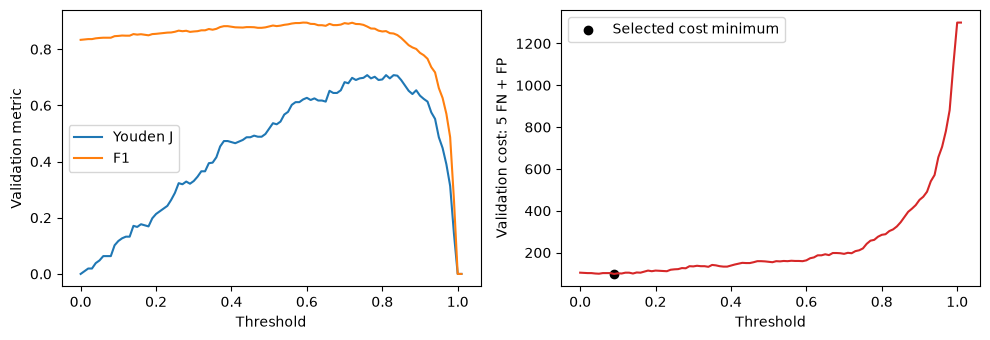

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(grid['threshold'], grid['J'], label='Youden J')
axes[0].plot(grid['threshold'], grid['F1'], label='F1')
axes[0].set(xlabel='Threshold', ylabel='Validation metric')
axes[0].legend()

axes[1].plot(grid['threshold'], grid['cost'], color='tab:red')

best_t = thresholds['Cost (5, 1)']
best_cost = summary.loc['Cost (5, 1)', 'cost']
axes[1].scatter(best_t, best_cost, color='black', label='Selected cost minimum')

axes[1].set(xlabel='Threshold', ylabel='Validation cost: 5 FN + FP')
axes[1].legend()

plt.tight_layout()
plt.show()

The threshold curves visually demonstrate the conflict between standard evaluation metrics and asymmetric custom costs. While the F1 score and Youden J statistic peak at mid-to-high thresholds, the custom cost function—which heavily penalizes false negatives—forces the optimal decision boundary (black dot) down to nearly 0.1 to avoid the exponential spike in costs that occurs as the threshold approaches 1.0.

**Reduced Data Experiment**

In [13]:
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

full_auc = {}
for name, model in models.items():
    prob = model.predict_proba(X_val_scaled)[:, 1]
    full_auc[name] = roc_auc_score(y_val, prob)

reduced, unused = train_test_split(
    fit, train_size=0.20, stratify=fit['y'], random_state=1601
)

print("--- Class Counts ---")
counts = pd.DataFrame({
    'All training rows': fit['y'].value_counts(),
    '20% of training rows': reduced['y'].value_counts(),
    'Validation': validation['y'].value_counts(),
}).sort_index()
counts.index.name = 'Class'
display(counts)

reduced_scaler = StandardScaler()
X_reduced = reduced_scaler.fit_transform(reduced[features])
X_validation_reduced = reduced_scaler.transform(validation[features])

reduced_auc = {}
for name, model in models.items():
    reduced_model = clone(model)
    reduced_model.fit(X_reduced, reduced['y'])
    
    probability = reduced_model.predict_proba(X_validation_reduced)[:, 1]
    reduced_auc[name] = roc_auc_score(y_val, probability)

comparison = pd.DataFrame({
    'Validation AUC (all training rows)': full_auc,
    'Validation AUC (20% of training rows)': reduced_auc,
})
comparison['AUC decrease'] = (
    comparison['Validation AUC (all training rows)'] - comparison['Validation AUC (20% of training rows)']
)

print("\n--- AUC Comparison ---")
display(comparison)

--- Class Counts ---


,All training rows,20% of training rows,Validation
Class,,,
0,311,62,104
1,778,155,260



--- AUC Comparison ---


,Validation AUC (all training rows),Validation AUC (20% of training rows),AUC decrease
Logistic,0.908,0.889,0.019
LDA,0.907,0.843,0.064
QDA,0.891,0.650,0.241


When the training data is drastically reduced to just 20% (leaving only 62 and 155 samples for the two classes), the complex QDA model completely collapses, suffering a massive AUC drop of 0.241 down to 0.650. In stark contrast, the simpler Logistic Regression model proves remarkably resilient to data scarcity, maintaining its strong predictive performance with a negligible AUC decrease of just 0.019. This stark divergence highlights that while complex models like QDA are highly susceptible to overfitting on small datasets, simpler linear models remain robust even when training data is severely limited.